
## 1. Import Data IHSG dari Yahoo Finance

Data historis Indeks Harga Saham Gabungan (IHSG) diperoleh dari Yahoo Finance menggunakan ticker JKSE. Data yang digunakan merupakan data harian dengan variabel Open, High, Low, Close, dan Volume (OHLCV).

Pengambilan data dilakukan menggunakan library yfinance. Data kemudian dibatasi pada kolom OHLCV yang diperlukan untuk tahap preprocessing, analisis statistik deskriptif, feature engineering, dan pemodelan regresi Gamma.

Periode pengamatan ditetapkan selama lima tahun terakhir agar analisis mencakup beragam kondisi pergerakan pasar.


In [ ]:
# Import library
!pip -q install yfinance

import yfinance as yf
import pandas as pd

# Menentukan ticker dan periode data
ticker = "^JKSE"
tanggal_mulai = "2021-10-23"
tanggal_akhir = "2026-10-24"  # Yahoo Finance: end bersifat eksklusif

# Mengunduh data IHSG harian
ihsg = yf.download(
    ticker,
    start=tanggal_mulai,
    end=tanggal_akhir,
    interval="1d",
    auto_adjust=False,
    progress=False
)

# Memeriksa apakah data berhasil diunduh
if ihsg.empty:
    raise ValueError(
        "Data IHSG kosong. Periksa koneksi internet atau ketersediaan data."
    )

# Menangani nama kolom bertingkat dari yfinance
if isinstance(ihsg.columns, pd.MultiIndex):
    ihsg.columns = ihsg.columns.get_level_values(0)

# Memilih kolom OHLCV
kolom = ["Open", "High", "Low", "Close", "Volume"]
ihsg = ihsg[kolom].copy()

# Menampilkan informasi dataset
print("Dimensi data:", ihsg.shape)
print("Periode awal:", ihsg.index.min().date())
print("Periode akhir:", ihsg.index.max().date())
print("Jumlah observasi:", len(ihsg))

# Menampilkan beberapa baris data
display(ihsg.head())
display(ihsg.tail())

Dimensi data: (1200, 5)
Periode awal: 2021-10-25
Periode akhir: 2026-10-23
Jumlah observasi: 1200


Price,Open,High,Low,Close,Volume
Date,,,,,
2021-10-25,6626.367188,6673.515137,6625.696777,6625.696777,175632400
2021-10-26,6640.051758,6680.117188,6638.027832,6656.937012,180194900
2021-10-27,6664.373047,6670.809082,6590.504883,6602.208984,182503600
2021-10-28,6578.583008,6600.247070,6509.877930,6524.076172,189347200
2021-10-29,6561.712891,6596.769043,6551.539062,6591.346191,171512200


Price,Open,High,Low,Close,Volume
Date,,,,,
2026-10-19,4961.875000,5012.869141,4907.370117,4996.608887,279060000
2026-10-20,4980.163086,5278.888184,4980.163086,5278.888184,534990700
2026-10-21,5310.848145,5328.359863,5185.359863,5328.359863,292010300
2026-10-22,5247.979004,5422.586914,5185.526855,5387.904785,356924900
2026-10-23,5397.336914,5455.210938,5366.293945,5439.257812,397036500



## 2. Data Preprocessing

Data preprocessing dilakukan untuk memastikan kualitas dan konsistensi data historis IHSG sebelum analisis lebih lanjut. Tahapan yang dilakukan meliputi:

1. Memeriksa dan menyesuaikan tipe data setiap variabel.
2. Memastikan indeks tanggal bertipe datetime dan tersusun secara kronologis.
3. Mengidentifikasi missing values pada setiap kolom.
4. Mengidentifikasi data duplikat berdasarkan tanggal pengamatan.
5. Menangani data yang bermasalah sesuai dengan karakteristiknya.

Pemeriksaan ini penting agar hasil statistik deskriptif, feature engineering, dan pemodelan regresi Gamma tidak terganggu oleh kesalahan format atau kualitas data.

Data yang hilang tidak langsung diisi atau dihapus secara otomatis, karena nilai yang tidak tersedia, khususnya pada kolom Volume, perlu diperiksa terlebih dahulu.


In [ ]:

# ==========================================
# 2. DATA PREPROCESSING
# ==========================================

# 1. Memeriksa struktur dan tipe data
print("Informasi dataset sebelum preprocessing:")
ihsg.info()

print("\nTipe data setiap kolom:")
print(ihsg.dtypes)


# 2. Memastikan indeks tanggal bertipe datetime
ihsg.index = pd.to_datetime(ihsg.index)

# Menghapus informasi timezone jika ada
if ihsg.index.tz is not None:
    ihsg.index = ihsg.index.tz_localize(None)

# Mengurutkan data berdasarkan tanggal
ihsg = ihsg.sort_index()

print("\nTipe indeks tanggal:", ihsg.index.dtype)
print("Tanggal sudah terurut:", ihsg.index.is_monotonic_increasing)


# 3. Memastikan kolom OHLCV bertipe numerik
kolom = ["Open", "High", "Low", "Close", "Volume"]

for col in kolom:
    ihsg[col] = pd.to_numeric(ihsg[col], errors="coerce")


# 4. Memeriksa missing values
print("\nJumlah missing values per kolom:")
print(ihsg.isna().sum())

print("\nPersentase missing values (%):")
print((ihsg.isna().mean() * 100).round(2))


# 5. Memeriksa duplikasi tanggal
jumlah_duplikat = ihsg.index.duplicated().sum()

print("\nJumlah tanggal duplikat:", jumlah_duplikat)

# Menghapus duplikasi tanggal jika ada,
# dengan mempertahankan kemunculan pertama
if jumlah_duplikat > 0:
    ihsg = ihsg.loc[~ihsg.index.duplicated(keep="first")]


# 6. Memeriksa duplikasi seluruh baris
print("Jumlah baris duplikat:", ihsg.duplicated().sum())


# 7. Menampilkan hasil setelah pemeriksaan
print("\nInformasi dataset setelah preprocessing:")
ihsg.info()

print("\nLima baris pertama:")
display(ihsg.head())

print("\nLima baris terakhir:")
display(ihsg.tail())

print("\nDimensi akhir:", ihsg.shape)


Informasi dataset sebelum preprocessing:
<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 1200 entries, 2021-10-25 to 2026-10-23
Data columns (total 5 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   Open    1200 non-null   float64
 1   High    1200 non-null   float64
 2   Low     1200 non-null   float64
 3   Close   1200 non-null   float64
 4   Volume  1200 non-null   int64  
dtypes: float64(4), int64(1)
memory usage: 56.2 KB

Tipe data setiap kolom:
Price
Open      float64
High      float64
Low       float64
Close     float64
Volume      int64
dtype: object

Tipe indeks tanggal: datetime64[ns]
Tanggal sudah terurut: True

Jumlah missing values per kolom:
Price
Open      0
High      0
Low       0
Close     0
Volume    0
dtype: int64

Persentase missing values (%):
Price
Open      0.0
High      0.0
Low       0.0
Close     0.0
Volume    0.0
dtype: float64

Jumlah tanggal duplikat: 0
Jumlah baris duplikat: 0

Informasi dataset setelah preproces

Price,Open,High,Low,Close,Volume
Date,,,,,
2021-10-25,6626.367188,6673.515137,6625.696777,6625.696777,175632400
2021-10-26,6640.051758,6680.117188,6638.027832,6656.937012,180194900
2021-10-27,6664.373047,6670.809082,6590.504883,6602.208984,182503600
2021-10-28,6578.583008,6600.247070,6509.877930,6524.076172,189347200
2021-10-29,6561.712891,6596.769043,6551.539062,6591.346191,171512200



Lima baris terakhir:


Price,Open,High,Low,Close,Volume
Date,,,,,
2026-10-19,4961.875000,5012.869141,4907.370117,4996.608887,279060000
2026-10-20,4980.163086,5278.888184,4980.163086,5278.888184,534990700
2026-10-21,5310.848145,5328.359863,5185.359863,5328.359863,292010300
2026-10-22,5247.979004,5422.586914,5185.526855,5387.904785,356924900
2026-10-23,5397.336914,5455.210938,5366.293945,5439.257812,397036500



Dimensi akhir: (1200, 5)



## 3. Statistik Deskriptif Data Awal

Statistik deskriptif dilakukan untuk mengetahui karakteristik data historis IHSG, meliputi jumlah observasi, rata-rata, standar deviasi, nilai minimum, kuartil, dan nilai maksimum. Analisis ini membantu mengidentifikasi rentang nilai, variasi data, serta kemungkinan adanya nilai ekstrem.

Visualisasi dilakukan untuk mengamati perkembangan harga pembukaan, harga tertinggi, harga terendah, harga penutupan, dan volume perdagangan sepanjang periode pengamatan.

Tahap ini memberikan gambaran umum mengenai kondisi pasar sebelum pembentukan variabel baru yang akan digunakan dalam regresi Gamma.


Statistik Deskriptif Data IHSG:


,count,mean,std,min,25%,50%,75%,max
Price,,,,,,,,
Open,1200.0,7.085618e+03,5.964564e+02,4961.875000,6.749325e+03,7.010338e+03,7.275133e+03,9.156189e+03
High,1200.0,7.124810e+03,5.934583e+02,5012.869141,6.790981e+03,7.048966e+03,7.313061e+03,9.174474e+03
Low,1200.0,7.034847e+03,5.946799e+02,4907.370117,6.704554e+03,6.965895e+03,7.238573e+03,9.120154e+03
Close,1200.0,7.079192e+03,5.940278e+02,4996.608887,6.748257e+03,7.004858e+03,7.277081e+03,9.134700e+03
Volume,1200.0,2.265728e+08,1.093261e+08,0.000000,1.545018e+08,1.921040e+08,2.629436e+08,1.155072e+09


Ringkasan Kualitas Data:


,Jumlah Data,Missing Values,Persentase Missing (%),Jumlah Nilai Unik
Price,,,,
Open,1200,0,0.0,1200
High,1200,0,0.0,1199
Low,1200,0,0.0,1200
Close,1200,0,0.0,1200
Volume,1200,0,0.0,1199


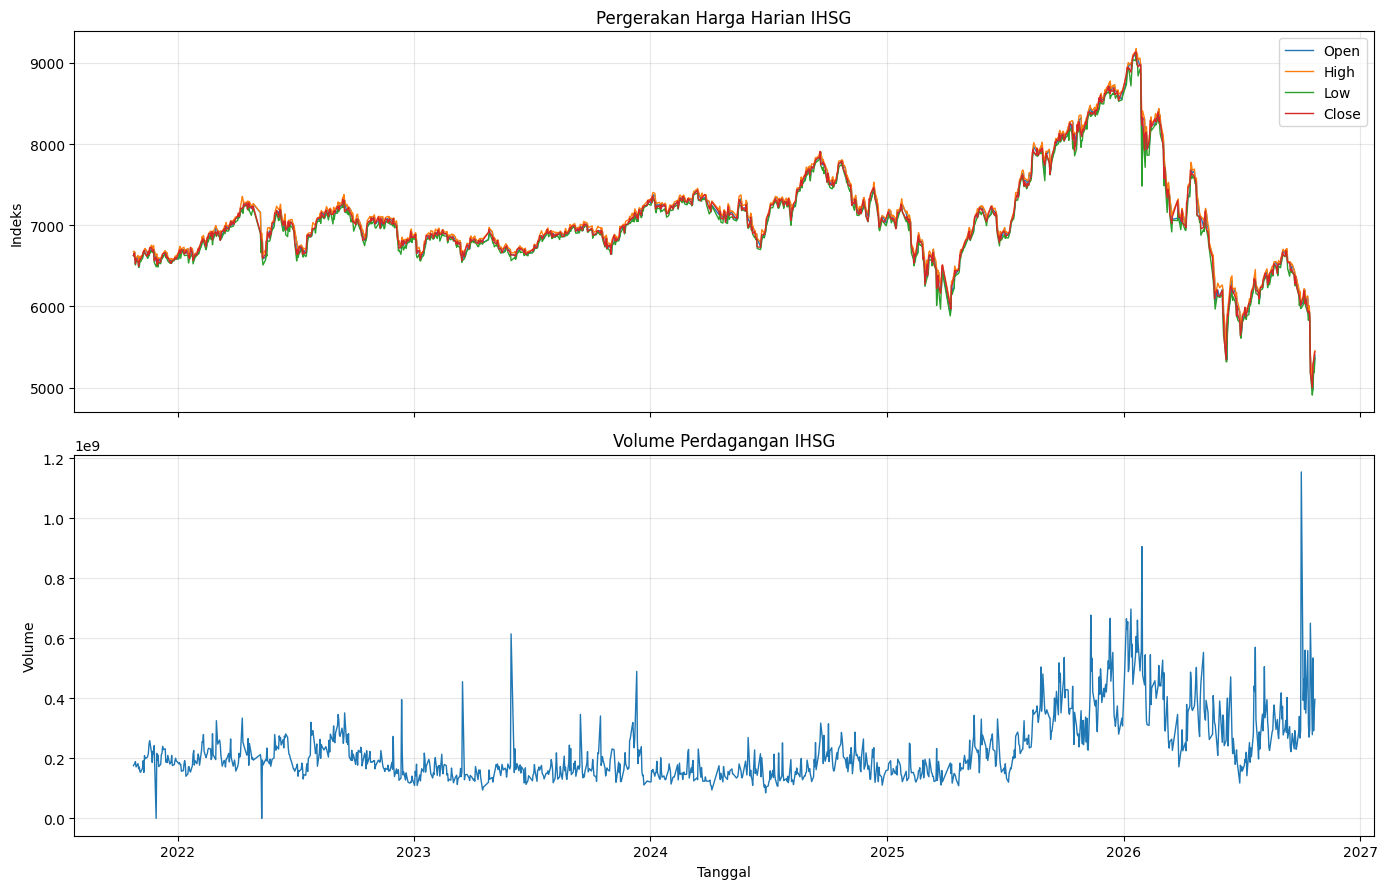

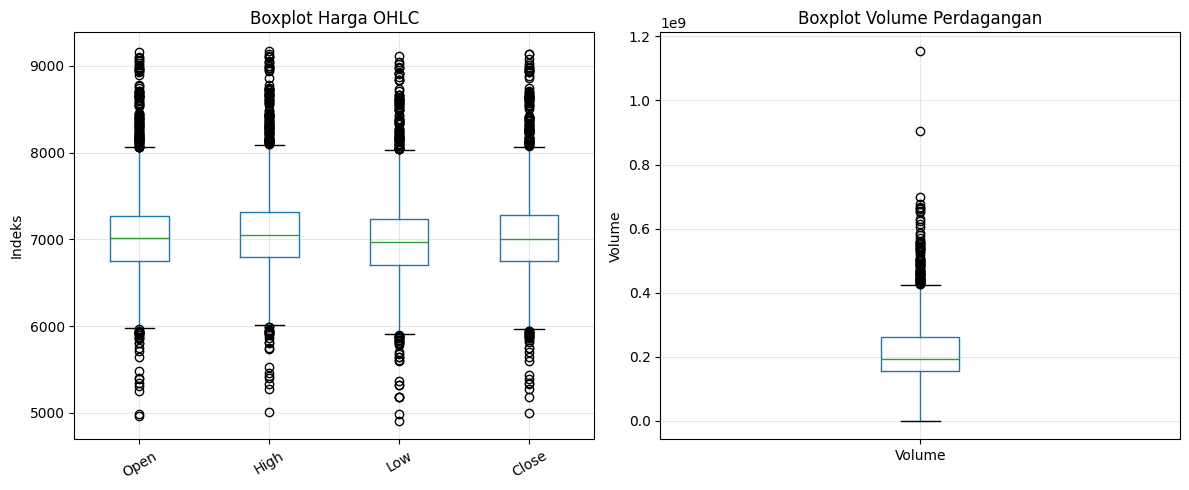

In [ ]:

# ==========================================
# 3. STATISTIK DESKRIPTIF DATA AWAL
# ==========================================

import matplotlib.pyplot as plt
import pandas as pd

# 1. Statistik deskriptif OHLCV
print("Statistik Deskriptif Data IHSG:")
display(ihsg.describe().T)

# 2. Memeriksa jumlah data dan missing values
ringkasan = pd.DataFrame({
    "Jumlah Data": ihsg.count(),
    "Missing Values": ihsg.isna().sum(),
    "Persentase Missing (%)": (ihsg.isna().mean() * 100).round(2),
    "Jumlah Nilai Unik": ihsg.nunique()
})

print("Ringkasan Kualitas Data:")
display(ringkasan)


# 3. Visualisasi harga OHLC
fig, axes = plt.subplots(
    nrows=2,
    ncols=1,
    figsize=(14, 9),
    sharex=True
)

kolom_harga = ["Open", "High", "Low", "Close"]

for col in kolom_harga:
    axes[0].plot(
        ihsg.index,
        ihsg[col],
        label=col,
        linewidth=1
    )

axes[0].set_title("Pergerakan Harga Harian IHSG")
axes[0].set_ylabel("Indeks")
axes[0].legend()
axes[0].grid(True, alpha=0.3)

# 4. Visualisasi volume perdagangan
axes[1].plot(
    ihsg.index,
    ihsg["Volume"],
    linewidth=1
)

axes[1].set_title("Volume Perdagangan IHSG")
axes[1].set_xlabel("Tanggal")
axes[1].set_ylabel("Volume")
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()


# 5. Boxplot untuk melihat sebaran dan nilai ekstrem
fig, axes = plt.subplots(
    nrows=1,
    ncols=2,
    figsize=(12, 5)
)

ihsg[kolom_harga].boxplot(ax=axes[0])
axes[0].set_title("Boxplot Harga OHLC")
axes[0].set_ylabel("Indeks")
axes[0].tick_params(axis="x", rotation=30)
axes[0].grid(True, alpha=0.3)

ihsg[["Volume"]].boxplot(ax=axes[1])
axes[1].set_title("Boxplot Volume Perdagangan")
axes[1].set_ylabel("Volume")
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()


### 4. Feature Engineering

Feature engineering merupakan proses membentuk variabel baru dari data yang tersedia agar lebih relevan dengan tujuan pemodelan. Pada penelitian ini, feature engineering dilakukan untuk membentuk variabel target yang merepresentasikan besarnya pergerakan harga IHSG serta variabel prediktor yang berasal dari periode sebelumnya (lagged variables).

Variabel target dibentuk menggunakan selisih harga tertinggi (High) dan harga terendah (Low) pada hari yang sama, kemudian dibagi dengan harga penutupan (Close) pada hari sebelumnya. Normalisasi ini bertujuan untuk mengukur rentang pergerakan harga secara relatif, sehingga besarnya pergerakan tidak hanya bergantung pada tingkat indeks IHSG.

Prediktor yang digunakan meliputi return IHSG hari sebelumnya, volatilitas historis lima hari perdagangan, rentang pergerakan harga hari sebelumnya, serta volume perdagangan hari sebelumnya apabila data volume tersedia. Penggunaan variabel lagged bertujuan memastikan bahwa prediktor hanya memanfaatkan informasi yang telah tersedia sebelum periode target.

Variabel target harus bernilai positif untuk memenuhi persyaratan distribusi Gamma. Oleh karena itu, nilai target nol atau negatif perlu diperiksa sebelum pemodelan dilakukan.

In [ ]:
import numpy as np
import pandas as pd

# Membuat salinan data
data = ihsg.copy()

# 1. Menghitung return harian IHSG
data["Return"] = data["Close"].pct_change()

# 2. Membentuk target: rentang pergerakan harga relatif
data["Target_Range"] = (
    (data["High"] - data["Low"]) / data["Close"].shift(1)
)

# 3. Prediktor return hari sebelumnya
data["Lag_Return_1"] = data["Return"].shift(1)

# 4. Prediktor volatilitas historis 5 hari
data["Lag_Volatility_5"] = (
    data["Return"].rolling(window=5).std().shift(1)
)

# 5. Prediktor rentang harga hari sebelumnya
data["Lag_Range_1"] = data["Target_Range"].shift(1)

# 6. Prediktor volume hari sebelumnya
data["Lag_Volume_1"] = data["Volume"].shift(1)

# Menampilkan variabel hasil feature engineering
kolom_baru = [
    "Close",
    "Return",
    "Target_Range",
    "Lag_Return_1",
    "Lag_Volatility_5",
    "Lag_Range_1",
    "Lag_Volume_1"
]

display(data[kolom_baru].head(10))

Price,Close,Return,Target_Range,Lag_Return_1,Lag_Volatility_5,Lag_Range_1,Lag_Volume_1
Date,,,,,,,
2021-10-25,6625.696777,NaN,NaN,NaN,NaN,NaN,NaN
2021-10-26,6656.937012,0.004715,0.006352,NaN,NaN,NaN,175632400.0
2021-10-27,6602.208984,-0.008221,0.012063,0.004715,NaN,0.006352,180194900.0
2021-10-28,6524.076172,-0.011834,0.013688,-0.008221,NaN,0.012063,182503600.0
2021-10-29,6591.346191,0.010311,0.006933,-0.011834,NaN,0.013688,189347200.0
2021-11-01,6552.889160,-0.005834,0.011373,0.010311,NaN,0.006933,171512200.0
2021-11-02,6493.274902,-0.009097,0.014297,-0.005834,0.009309,0.011373,182528900.0
2021-11-03,6552.129883,0.009064,0.011791,-0.009097,0.008789,0.014297,165299300.0
2021-11-04,6586.442871,0.005237,0.005295,0.009064,0.010421,0.011791,171604200.0


In [ ]:
# Memeriksa nilai target
print("Jumlah target kosong:", data["Target_Range"].isna().sum())
print("Jumlah target nol:", (data["Target_Range"] == 0).sum())
print("Jumlah target negatif:", (data["Target_Range"] < 0).sum())

print("\nStatistik target:")
display(data["Target_Range"].describe())

# Menampilkan contoh target nol atau negatif
display(
    data.loc[
        data["Target_Range"].notna()
        & (data["Target_Range"] <= 0),
        ["High", "Low", "Close", "Target_Range"]
    ].head()
)

Jumlah target kosong: 1
Jumlah target nol: 0
Jumlah target negatif: 0

Statistik target:


,Target_Range
count,1199.000000
mean,0.012815
std,0.008208
min,0.003942
25%,0.007960
50%,0.010639
75%,0.014963
max,0.097945


Price,High,Low,Close,Target_Range
Date,,,,


### 5. Statistik Deskriptif Fitur Baru

Statistik deskriptif dilakukan untuk memahami karakteristik variabel yang telah dibentuk melalui proses feature engineering. Analisis ini mencakup ukuran pemusatan, penyebaran, dan rentang nilai melalui nilai rata-rata (mean), standar deviasi, nilai minimum, kuartil, median, dan maksimum.

Variabel yang dianalisis meliputi Target_Range sebagai variabel target, serta Lag_Return_1, Lag_Volatility_5, Lag_Range_1, dan Lag_Volume_1 sebagai variabel prediktor. Visualisasi menggunakan histogram dan boxplot untuk mengamati distribusi data, tingkat variasi, kemencengan distribusi, serta kemungkinan nilai ekstrem.

Hasil analisis digunakan untuk memahami karakteristik awal setiap variabel dan membantu menentukan langkah analisis berikutnya. Nilai ekstrem tidak langsung dianggap sebagai kesalahan karena dapat merepresentasikan kondisi pasar yang sebenarnya.

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Menentukan fitur yang akan dianalisis
fitur = [
    "Target_Range",
    "Lag_Return_1",
    "Lag_Volatility_5",
    "Lag_Range_1",
    "Lag_Volume_1"
]

# Statistik deskriptif
print("Statistik Deskriptif Fitur Baru:")
display(data[fitur].describe().T)

# Informasi tambahan
ringkasan_fitur = pd.DataFrame({
    "Jumlah Data": data[fitur].count(),
    "Missing Values": data[fitur].isna().sum(),
    "Persentase Missing (%)": (data[fitur].isna().mean() * 100).round(2),
    "Jumlah Nilai Unik": data[fitur].nunique()
})

print("Ringkasan Kualitas Fitur:")
display(ringkasan_fitur)

Statistik Deskriptif Fitur Baru:


,count,mean,std,min,25%,50%,75%,max
Price,,,,,,,,
Target_Range,1199.0,1.281473e-02,8.208161e-03,0.003942,7.960440e-03,1.063947e-02,1.496309e-02,9.794461e-02
Lag_Return_1,1198.0,-1.076240e-04,1.133868e-02,-0.115740,-5.074128e-03,4.343916e-04,5.661678e-03,7.572077e-02
Lag_Volatility_5,1194.0,8.863601e-03,6.910036e-03,0.001146,4.953013e-03,6.998418e-03,1.067133e-02,6.518258e-02
Lag_Range_1,1198.0,1.281165e-02,8.210896e-03,0.003942,7.960119e-03,1.063533e-02,1.494543e-02,9.794461e-02
Lag_Volume_1,1199.0,2.264307e+08,1.092607e+08,0.000000,1.544798e+08,1.920176e+08,2.627303e+08,1.155072e+09


Ringkasan Kualitas Fitur:


,Jumlah Data,Missing Values,Persentase Missing (%),Jumlah Nilai Unik
Price,,,,
Target_Range,1199,1,0.08,1199
Lag_Return_1,1198,2,0.17,1198
Lag_Volatility_5,1194,6,0.50,1194
Lag_Range_1,1198,2,0.17,1198
Lag_Volume_1,1199,1,0.08,1198


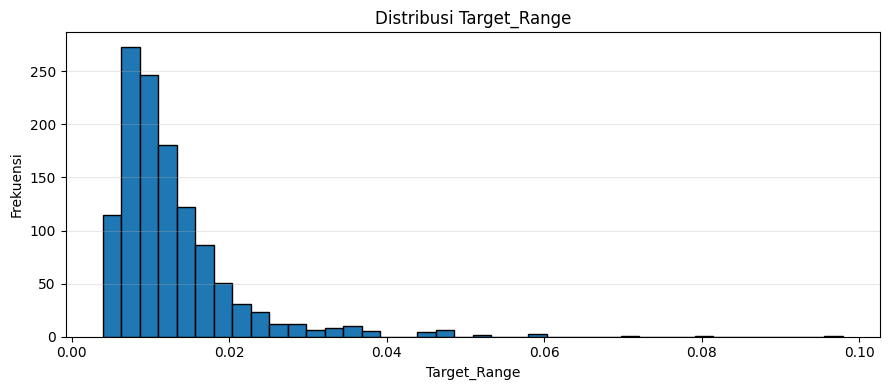

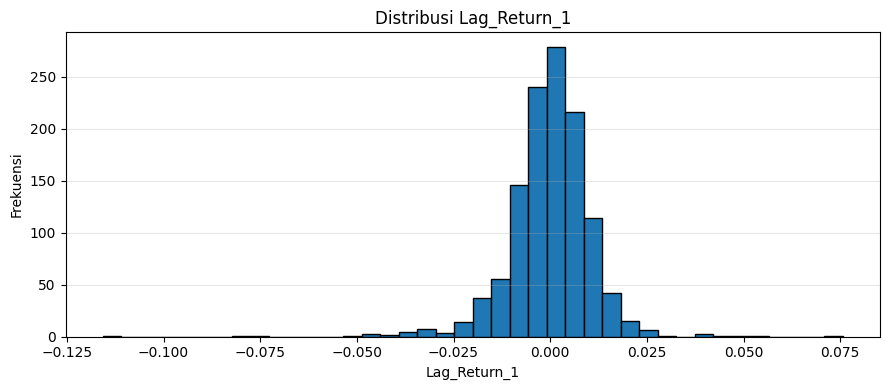

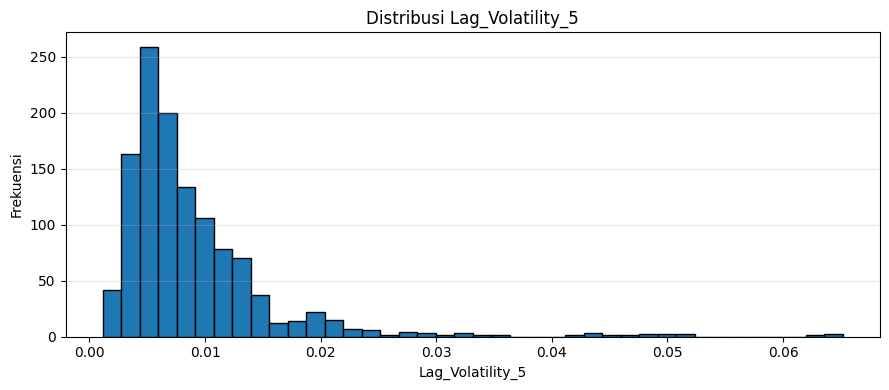

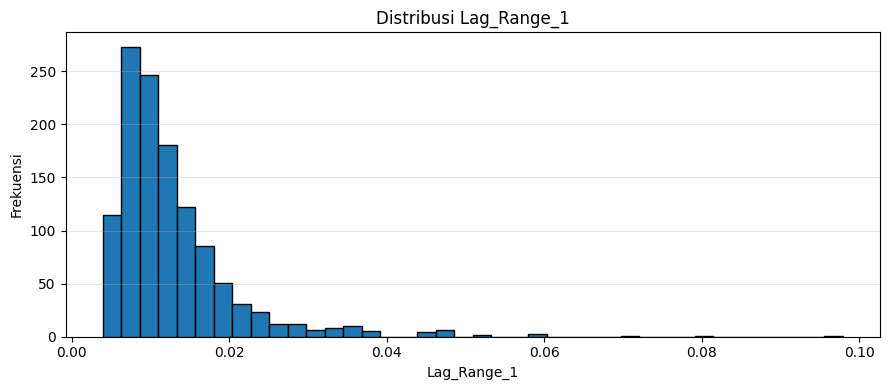

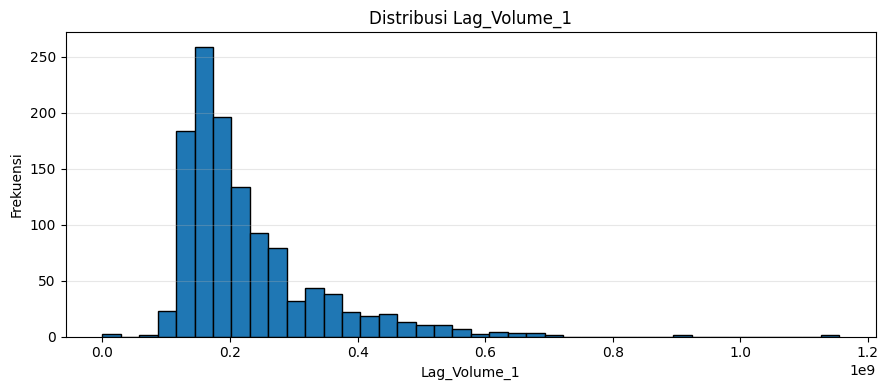

In [ ]:
# Histogram setiap fitur
for kolom in fitur:
    nilai = data[kolom].dropna()

    if len(nilai) == 0:
        print(f"{kolom}: tidak memiliki data valid.")
        continue

    plt.figure(figsize=(9, 4))
    plt.hist(nilai, bins=40, edgecolor="black")
    plt.title(f"Distribusi {kolom}")
    plt.xlabel(kolom)
    plt.ylabel("Frekuensi")
    plt.grid(axis="y", alpha=0.3)
    plt.tight_layout()
    plt.show()

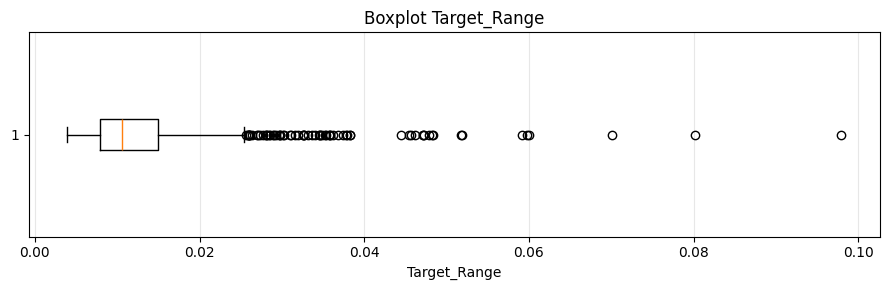

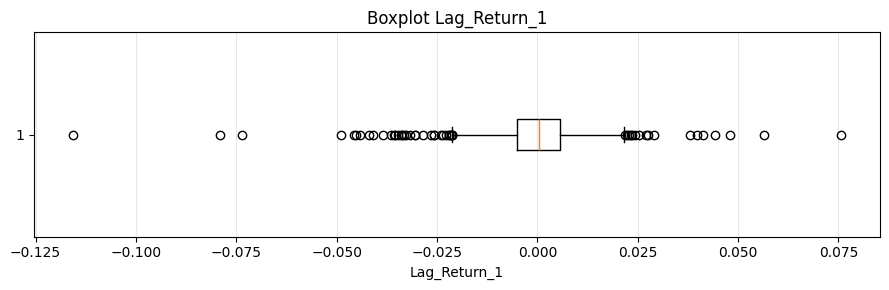

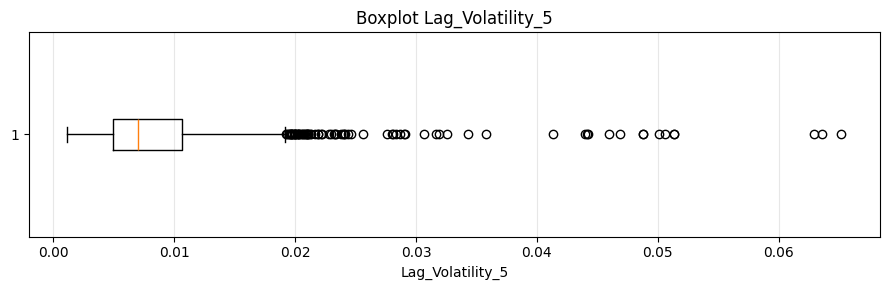

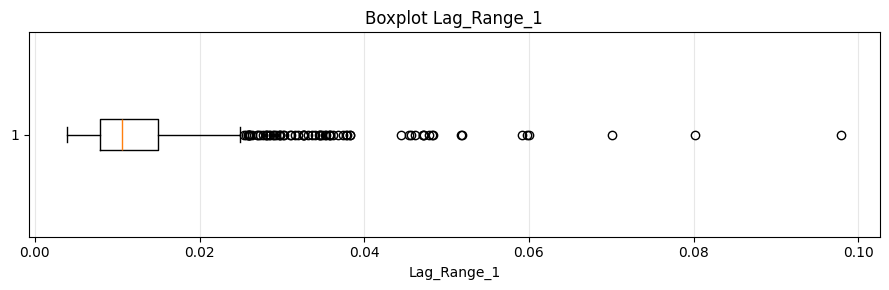

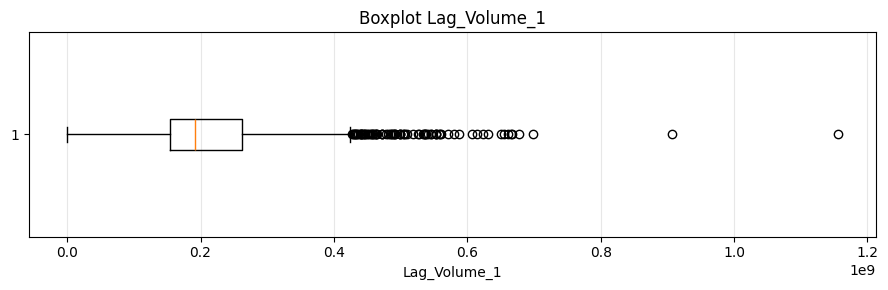

In [ ]:
#visualisasi boxplot
for kolom in fitur:
    nilai = data[kolom].dropna()

    if len(nilai) == 0:
        continue

    plt.figure(figsize=(9, 3))
    plt.boxplot(nilai, vert=False)
    plt.title(f"Boxplot {kolom}")
    plt.xlabel(kolom)
    plt.grid(axis="x", alpha=0.3)
    plt.tight_layout()
    plt.show()

In [ ]:
# Menghitung skewness Target_Range
skewness = data["Target_Range"].skew()

print("Skewness Target_Range:", round(skewness, 4))

if skewness > 0:
    print("Distribusi menceng ke kanan (positive skewness).")
elif skewness < 0:
    print("Distribusi menceng ke kiri (negative skewness).")
else:
    print("Distribusi memiliki skewness mendekati nol.")

Skewness Target_Range: 3.4588
Distribusi menceng ke kanan (positive skewness).


Berdasarkan hasil perhitungan, variabel Target_Range memiliki nilai skewness sebesar 3,4588, yang menunjukkan distribusi menceng ke kanan (positive skewness). Hal ini mengindikasikan bahwa sebagian besar observasi memiliki rentang pergerakan harga relatif kecil, sedangkan sebagian kecil observasi memiliki rentang pergerakan yang jauh lebih besar. Kondisi tersebut menunjukkan adanya variasi besaran pergerakan IHSG antarhari dan menjadi karakteristik awal yang perlu dipertimbangkan dalam pemodelan regresi Gamma.

### 6. Exploratory Data Analysis (EDA)

Exploratory Data Analysis (EDA) merupakan tahap eksplorasi data untuk memahami distribusi, tren, hubungan antarvariabel, dan pola temporal pada data IHSG. Analisis ini dilakukan untuk mengidentifikasi karakteristik pergerakan harga serta pola yang berpotensi relevan dalam pemodelan regresi Gamma.

Analisis distribusi dilakukan melalui histogram untuk mengamati sebaran besarnya pergerakan harga. Analisis tren dilakukan dengan mengamati perkembangan harga penutupan IHSG dan target pergerakan harga sepanjang periode pengamatan. Hubungan antarvariabel dieksplorasi melalui scatter plot dan matriks korelasi untuk melihat pola hubungan antara target dan prediktor. Selanjutnya, pola waktu dianalisis untuk mengidentifikasi perubahan besarnya pergerakan harga dari waktu ke waktu.

Hasil EDA digunakan sebagai dasar untuk memahami karakteristik data dan menentukan variabel yang layak dipertimbangkan dalam pemodelan. Pola yang ditemukan merupakan indikasi awal dan tidak secara langsung menunjukkan hubungan sebab-akibat ataupun menjamin kemampuan prediksi model.

###6.2 Distribusi target

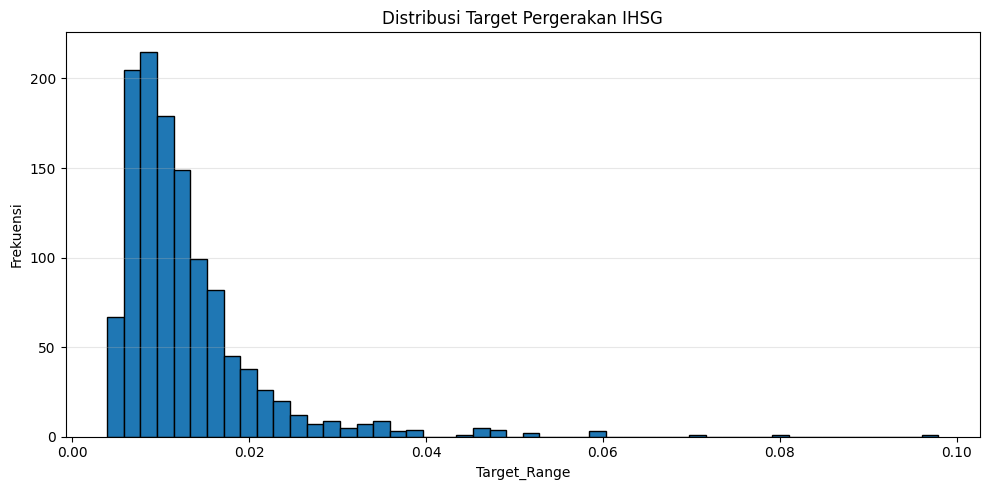

In [ ]:
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np

# Mengambil target yang valid
target_valid = data["Target_Range"].dropna()

plt.figure(figsize=(10, 5))
plt.hist(target_valid, bins=50, edgecolor="black")
plt.title("Distribusi Target Pergerakan IHSG")
plt.xlabel("Target_Range")
plt.ylabel("Frekuensi")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

###6.3 Tren harga IHSG dan target dari waktu ke waktu

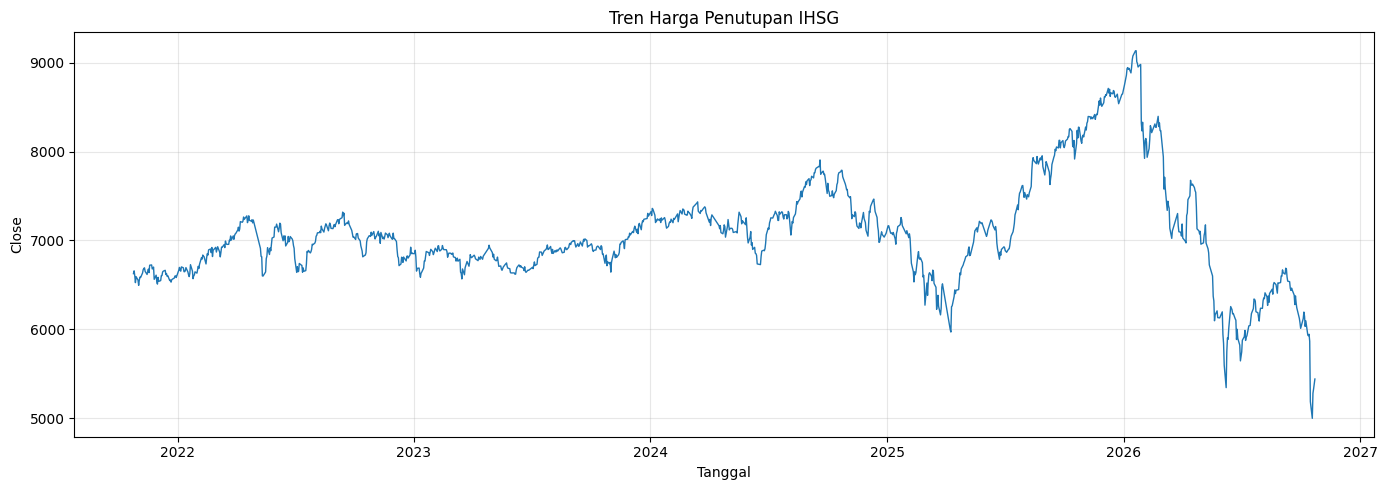

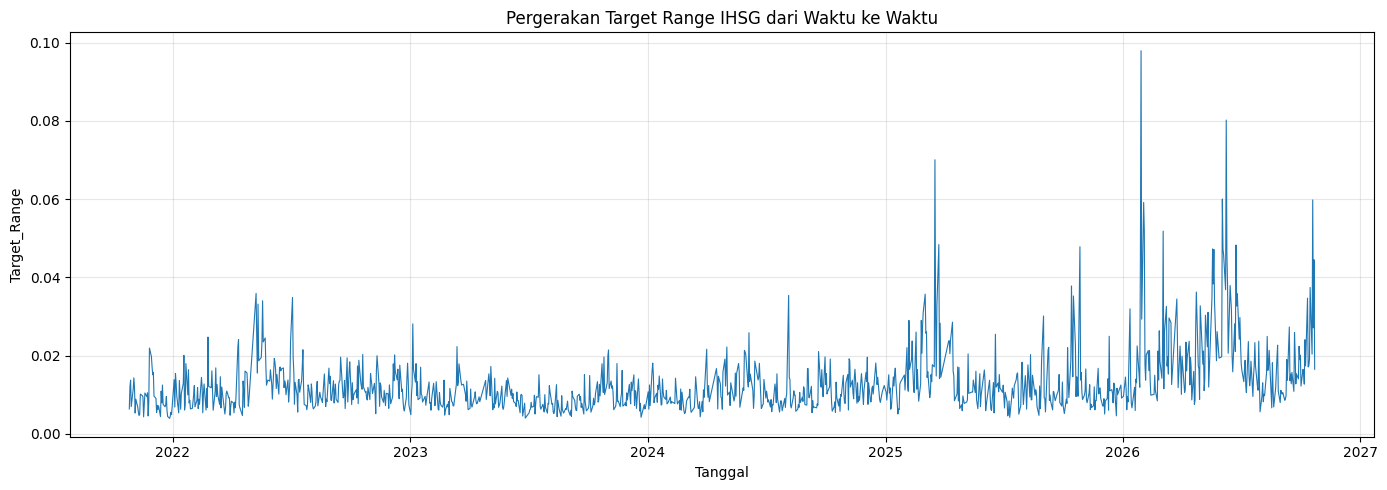

In [ ]:
# Grafik tren harga penutupan IHSG
plt.figure(figsize=(14, 5))
plt.plot(data.index, data["Close"], linewidth=1)
plt.title("Tren Harga Penutupan IHSG")
plt.xlabel("Tanggal")
plt.ylabel("Close")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

# Grafik target pergerakan harga
plt.figure(figsize=(14, 5))
plt.plot(data.index, data["Target_Range"], linewidth=0.8)
plt.title("Pergerakan Target Range IHSG dari Waktu ke Waktu")
plt.xlabel("Tanggal")
plt.ylabel("Target_Range")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

###6.4 Pola waktu: perubahan pergerakan harga
Untuk melihat apakah terdapat periode ketika pergerakan IHSG cenderung lebih besar, kita gunakan rata-rata bergerak 20 hari perdagangan (20-day rolling mean).

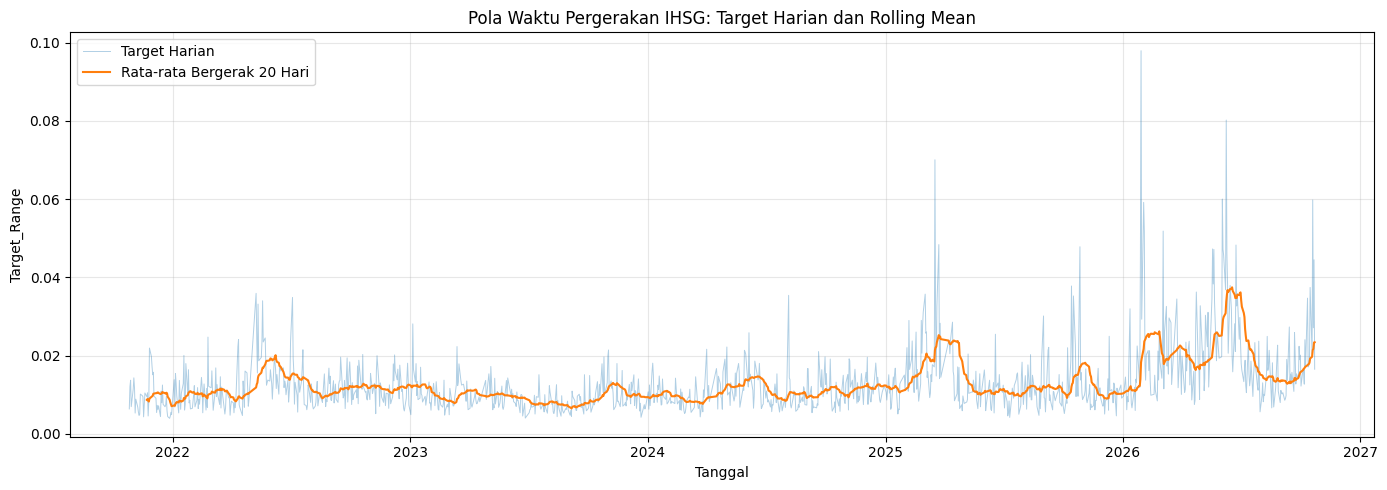

In [ ]:
# Menghitung rata-rata bergerak 20 hari untuk target
data["Target_Range_MA20"] = (
    data["Target_Range"].rolling(window=20).mean()
)

plt.figure(figsize=(14, 5))
plt.plot(
    data.index,
    data["Target_Range"],
    label="Target Harian",
    alpha=0.35,
    linewidth=0.7
)
plt.plot(
    data.index,
    data["Target_Range_MA20"],
    label="Rata-rata Bergerak 20 Hari",
    linewidth=1.5
)

plt.title("Pola Waktu Pergerakan IHSG: Target Harian dan Rolling Mean")
plt.xlabel("Tanggal")
plt.ylabel("Target_Range")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

###6.5 Hubungan target dengan prediktor
Gunakan scatter plot untuk melihat apakah target memiliki pola hubungan dengan prediktor yang telah dibuat.

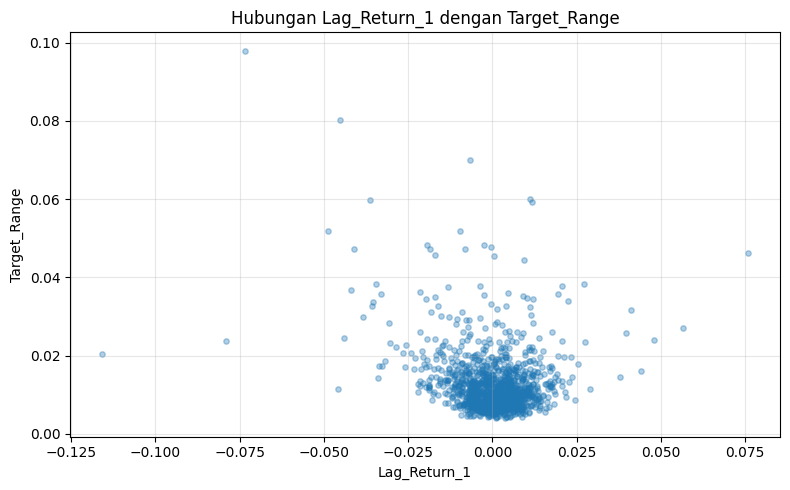

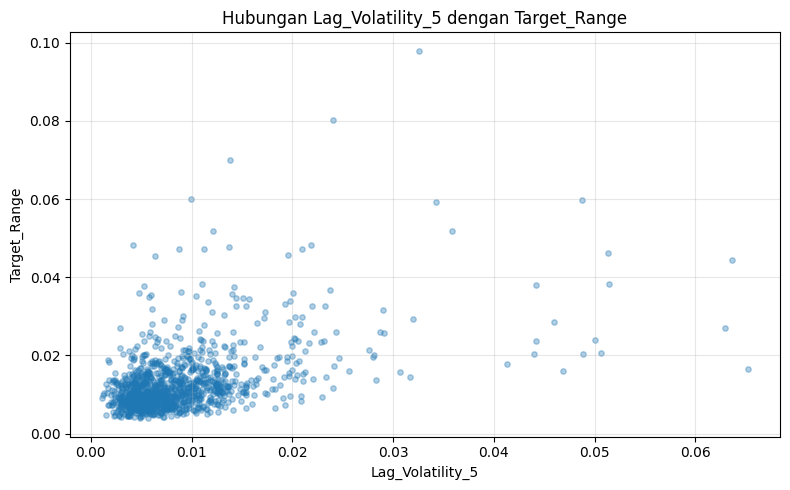

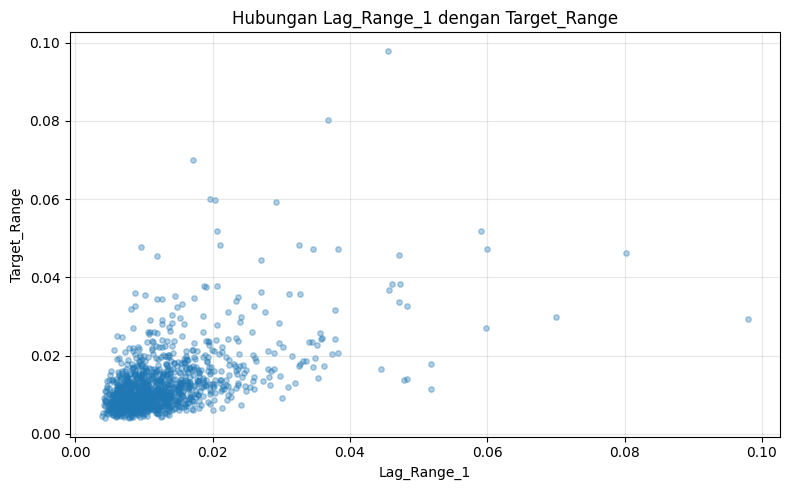

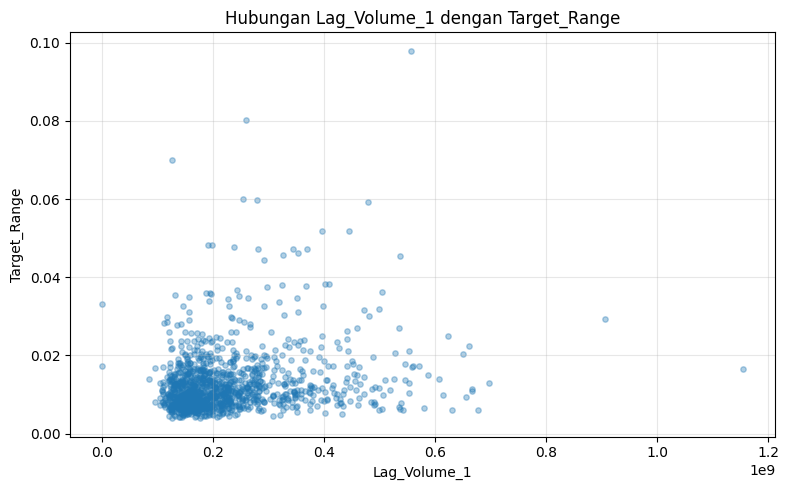

In [ ]:
# Prediktor yang akan dianalisis
prediktor = [
    "Lag_Return_1",
    "Lag_Volatility_5",
    "Lag_Range_1",
    "Lag_Volume_1"
]

for kolom in prediktor:
    # Mengambil baris yang memiliki target dan prediktor valid
    subset = data[["Target_Range", kolom]].dropna()

    if subset.empty:
        print(f"{kolom}: tidak memiliki data lengkap untuk dianalisis.")
        continue

    plt.figure(figsize=(8, 5))
    plt.scatter(
        subset[kolom],
        subset["Target_Range"],
        alpha=0.35,
        s=15
    )
    plt.title(f"Hubungan {kolom} dengan Target_Range")
    plt.xlabel(kolom)
    plt.ylabel("Target_Range")
    plt.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.show()

###6.6 Korelasi antarvariabel
Korelasi membantu mengidentifikasi hubungan linear antarvariabel dan kemungkinan multikolinearitas awal antarfitur.

Price,Target_Range,Lag_Return_1,Lag_Volatility_5,Lag_Range_1,Lag_Volume_1
Price,,,,,
Target_Range,1.000,-0.221,0.483,0.532,0.216
Lag_Return_1,-0.221,1.000,-0.021,-0.268,-0.051
Lag_Volatility_5,0.483,-0.021,1.000,0.634,0.189
Lag_Range_1,0.532,-0.268,0.634,1.000,0.303
Lag_Volume_1,0.216,-0.051,0.189,0.303,1.000


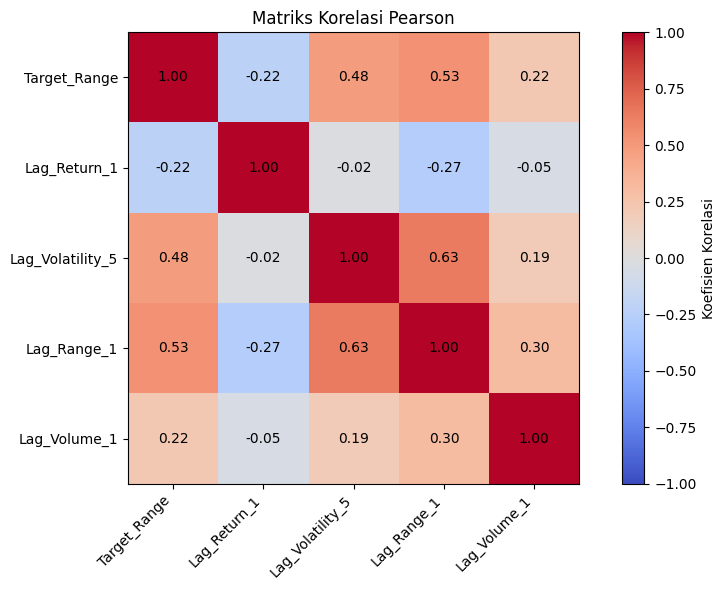

In [ ]:
# Memilih target dan prediktor
kolom_korelasi = [
    "Target_Range",
    "Lag_Return_1",
    "Lag_Volatility_5",
    "Lag_Range_1",
    "Lag_Volume_1"
]

# Menghapus kolom yang seluruh nilainya kosong
kolom_korelasi = [
    kolom for kolom in kolom_korelasi
    if data[kolom].notna().any()
]

# Menghitung korelasi Pearson
matriks_korelasi = data[kolom_korelasi].corr()

display(matriks_korelasi.round(3))

# Visualisasi heatmap menggunakan Matplotlib
fig, ax = plt.subplots(figsize=(9, 6))

im = ax.imshow(
    matriks_korelasi,
    cmap="coolwarm",
    vmin=-1,
    vmax=1
)

ax.set_xticks(range(len(kolom_korelasi)))
ax.set_xticklabels(kolom_korelasi, rotation=45, ha="right")
ax.set_yticks(range(len(kolom_korelasi)))
ax.set_yticklabels(kolom_korelasi)

for i in range(len(kolom_korelasi)):
    for j in range(len(kolom_korelasi)):
        nilai = matriks_korelasi.iloc[i, j]
        if pd.notna(nilai):
            ax.text(
                j, i, f"{nilai:.2f}",
                ha="center", va="center"
            )

ax.set_title("Matriks Korelasi Pearson")
fig.colorbar(im, ax=ax, label="Koefisien Korelasi")
plt.tight_layout()
plt.show()

### Kesimpulan Exploratory Data Analysis (EDA)

Hasil Exploratory Data Analysis menunjukkan bahwa variabel Target_Range memiliki distribusi menceng ke kanan (right-skewed), yang mengindikasikan bahwa sebagian besar rentang pergerakan harga IHSG relatif kecil, sedangkan sebagian kecil observasi memiliki rentang pergerakan yang jauh lebih besar.

Berdasarkan grafik tren dan pola waktu, periode 2022–2024 menunjukkan karakteristik pergerakan yang relatif lebih rendah dibandingkan periode 2025–2026. Pada periode 2025–2026, rata-rata bergerak 20 hari dari rentang pergerakan harga menunjukkan peningkatan, yang mengindikasikan membesarnya rentang pergerakan harga pada periode tersebut.

Analisis korelasi menunjukkan bahwa Target_Range dan Lag_Range_1 memiliki korelasi positif sebesar 0,53. Temuan ini mengindikasikan adanya hubungan linear positif dengan kekuatan sedang antara rentang pergerakan harga pada hari sebelumnya dan rentang pergerakan harga pada hari pengamatan.

Selain itu, data volume perdagangan tidak menunjukkan nilai kosong berdasarkan pemeriksaan yang dilakukan. Oleh karena itu, volume dapat dipertimbangkan sebagai kandidat prediktor, dengan tetap memperhatikan validitas dan relevansinya terhadap target penelitian.

Secara keseluruhan, hasil EDA menunjukkan adanya variasi besaran pergerakan IHSG dari waktu ke waktu serta indikasi hubungan antara pergerakan harga pada periode sebelumnya dan periode berikutnya. Temuan ini menjadi dasar untuk melanjutkan pemeriksaan kelayakan variabel dan diagnostik sebelum membangun model regresi Gamma.

### 7. Pemeriksaan Asumsi dan Diagnostik Regresi Gamma

Pemeriksaan asumsi dan diagnostik dilakukan untuk menilai kelayakan data serta mengevaluasi spesifikasi model regresi Gamma. Pemeriksaan meliputi positivitas variabel target, multikolinearitas antarvariabel prediktor, kesesuaian spesifikasi model, dan pola residual.

Variabel target pada regresi Gamma harus bernilai positif. Multikolinearitas diperiksa menggunakan Variance Inflation Factor (VIF) untuk mengidentifikasi prediktor yang memiliki hubungan linear kuat dengan prediktor lainnya. Spesifikasi model dievaluasi melalui perbandingan nilai aktual dan prediksi serta pemeriksaan pola residual. Diagnostik residual digunakan untuk mengidentifikasi pola kesalahan sistematis, perubahan varians, dan kemungkinan ketergantungan residual dari waktu ke waktu.

Model awal menggunakan Generalized Linear Model (GLM) dengan distribusi Gamma dan fungsi penghubung log (*log link*). Karena data IHSG berbentuk deret waktu, data disusun secara kronologis dan bagian awal periode digunakan untuk pemeriksaan model awal. Evaluasi prediksi pada periode yang lebih baru dilakukan pada tahap evaluasi model.

Regresi Gamma tidak mensyaratkan residual berdistribusi normal seperti regresi linear klasik. Oleh karena itu, pemeriksaan normalitas residual bukan syarat utama dalam tahap ini.

###7.2 Pemeriksaan positivitas target

In [ ]:
# Memeriksa target sebelum pemodelan
target = data["Target_Range"]

print("Jumlah target kosong:", target.isna().sum())
print("Jumlah target <= 0:", (target <= 0).sum())
print("Jumlah target positif:", (target > 0).sum())

if target.dropna().empty:
    print("Target tidak memiliki data valid.")
elif (target.dropna() <= 0).any():
    print("Perhatian: terdapat target nol atau negatif.")
else:
    print("Semua target yang tersedia bernilai positif.")

Jumlah target kosong: 1
Jumlah target <= 0: 0
Jumlah target positif: 1199
Semua target yang tersedia bernilai positif.


###7.3 Menyiapkan prediktor dan membagi data berdasarkan waktu

In [ ]:
import numpy as np
import pandas as pd

# Membuat salinan untuk pemodelan
model_data = data.copy()

# Transformasi volume hari sebelumnya
model_data["Lag_Log_Volume_1"] = np.log1p(
    model_data["Lag_Volume_1"].where(
        model_data["Lag_Volume_1"] >= 0
    )
)

# Menentukan target dan prediktor
target_col = "Target_Range"

fitur_model = [
    "Lag_Return_1",
    "Lag_Volatility_5",
    "Lag_Range_1",
    "Lag_Log_Volume_1"
]

# Memilih kolom yang diperlukan
model_data = model_data[[target_col] + fitur_model].copy()

# Mengubah nilai tak hingga menjadi missing value
model_data = model_data.replace([np.inf, -np.inf], np.nan)

# Hanya mempertahankan baris dengan data lengkap dan target positif
model_data = model_data.dropna()
model_data = model_data.loc[model_data[target_col] > 0]
model_data = model_data.sort_index()

# Membagi data secara kronologis: 80% awal untuk pelatihan
batas = int(len(model_data) * 0.8)

train = model_data.iloc[:batas].copy()
test = model_data.iloc[batas:].copy()

print("Jumlah observasi valid:", len(model_data))
print("Jumlah data training:", len(train))
print("Jumlah data testing:", len(test))
print("Periode training:", train.index.min().date(), "sampai", train.index.max().date())
print("Periode testing:", test.index.min().date(), "sampai", test.index.max().date())

Jumlah observasi valid: 1194
Jumlah data training: 955
Jumlah data testing: 239
Periode training: 2021-11-02 sampai 2025-10-23
Periode testing: 2025-10-24 sampai 2026-10-23


###7.4 Pemeriksaan multikolinearitas menggunakan VIF

In [ ]:
import statsmodels.api as sm
from statsmodels.stats.outliers_influence import variance_inflation_factor

X_train = train[fitur_model].astype(float)
X_train_const = sm.add_constant(X_train)

hasil_vif = pd.DataFrame({
    "Variabel": X_train_const.columns,
    "VIF": [
        variance_inflation_factor(
            X_train_const.values, i
        )
        for i in range(X_train_const.shape[1])
    ]
})

display(hasil_vif.round(3))

,Variabel,VIF
0,const,1.000
1,Lag_Return_1,1.148
2,Lag_Volatility_5,1.452
3,Lag_Range_1,1.590
4,Lag_Log_Volume_1,1.007


###7.5 Membentuk model Gamma awal

In [ ]:
import statsmodels.api as sm

# Menyiapkan target dan prediktor training
y_train = train[target_col].astype(float)
X_train = train[fitur_model].astype(float)

# Menambahkan konstanta
X_train_const = sm.add_constant(X_train)

# Membentuk dan melatih model Gamma
model_gamma = sm.GLM(
    y_train,
    X_train_const,
    family=sm.families.Gamma(
        link=sm.families.links.Log()
    )
)

hasil_gamma = model_gamma.fit()

# Menampilkan hasil estimasi
print(hasil_gamma.summary())

                 Generalized Linear Model Regression Results                  
Dep. Variable:           Target_Range   No. Observations:                  955
Model:                            GLM   Df Residuals:                      950
Model Family:                   Gamma   Df Model:                            4
Link Function:                    Log   Scale:                         0.18057
Method:                          IRLS   Log-Likelihood:                 3909.3
Date:                Fri, 30 Oct 2026   Deviance:                       139.99
Time:                        04:07:44   Pearson chi2:                     172.
No. Iterations:                    11   Pseudo R-squ. (CS):             0.2110
Covariance Type:            nonrobust                                         
                       coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------------
const               -4.4909      0.287  

###7.6 Pemeriksaan spesifikasi model dan residual

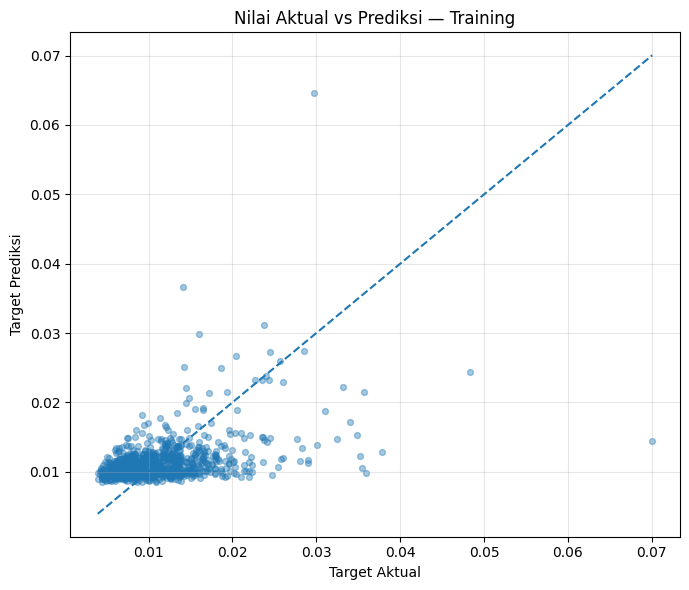

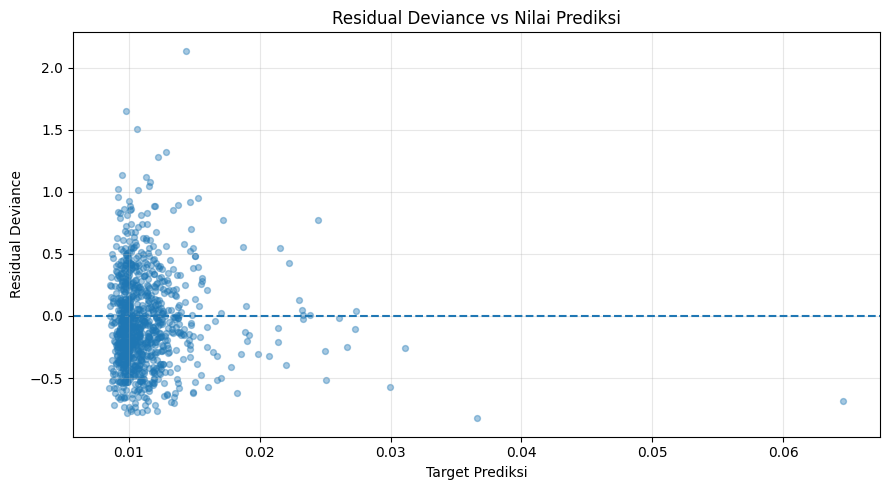

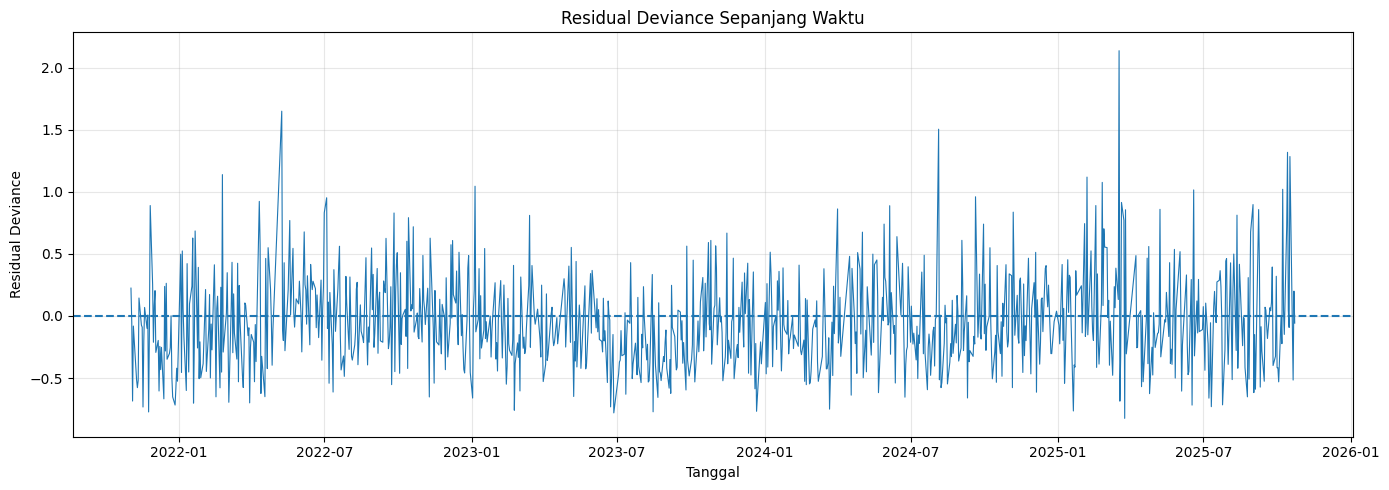

In [ ]:
# Prediksi pada data training
pred_train = hasil_gamma.predict(X_train_const)

# Residual deviance dan Pearson
resid_deviance = hasil_gamma.resid_deviance
resid_pearson = hasil_gamma.resid_pearson

# 1. Nilai aktual vs prediksi
plt.figure(figsize=(7, 6))
plt.scatter(y_train, pred_train, alpha=0.4, s=18)

batas_min = min(y_train.min(), pred_train.min())
batas_max = max(y_train.max(), pred_train.max())

plt.plot(
    [batas_min, batas_max],
    [batas_min, batas_max],
    linestyle="--"
)

plt.xlabel("Target Aktual")
plt.ylabel("Target Prediksi")
plt.title("Nilai Aktual vs Prediksi — Training")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

# 2. Residual deviance vs nilai prediksi
plt.figure(figsize=(9, 5))
plt.scatter(pred_train, resid_deviance, alpha=0.4, s=18)
plt.axhline(0, linestyle="--")
plt.xlabel("Target Prediksi")
plt.ylabel("Residual Deviance")
plt.title("Residual Deviance vs Nilai Prediksi")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

# 3. Residual deviance sepanjang waktu
plt.figure(figsize=(14, 5))
plt.plot(train.index, resid_deviance, linewidth=0.8)
plt.axhline(0, linestyle="--")
plt.xlabel("Tanggal")
plt.ylabel("Residual Deviance")
plt.title("Residual Deviance Sepanjang Waktu")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

###7.7 Memeriksa ketergantungan residual dari waktu ke waktu
Data finansial sering memiliki ketergantungan temporal. Memeriksa autokorelasi residual menggunakan Durbin–Watson dan uji Ljung–Box.

In [ ]:
from statsmodels.stats.stattools import durbin_watson
from statsmodels.stats.diagnostic import acorr_ljungbox

# Statistik Durbin-Watson
dw = durbin_watson(resid_pearson)

print("Durbin-Watson:", round(dw, 4))

# Uji Ljung-Box pada beberapa lag
lag_maks = min(10, len(resid_pearson) // 5)

if lag_maks >= 1:
    hasil_ljungbox = acorr_ljungbox(
        resid_pearson,
        lags=[lag_maks],
        return_df=True
    )
    display(hasil_ljungbox)

Durbin-Watson: 2.0487


,lb_stat,lb_pvalue
10,28.84362,0.001321


###7.8 Kesimpulan Pemeriksaan Asumsi dan Diagnostik

Hasil pemeriksaan menunjukkan bahwa variabel target memenuhi persyaratan dasar regresi Gamma karena seluruh observasi target yang digunakan bernilai positif. Pemeriksaan multikolinearitas menggunakan Variance Inflation Factor (VIF) juga menunjukkan nilai yang mendekati satu, sehingga tidak terdapat indikasi multikolinearitas yang berarti di antara variabel prediktor.

Pemeriksaan residual menunjukkan adanya variasi residual sepanjang periode pengamatan, termasuk nilai yang lebih besar pada periode 2025. Hasil uji Durbin–Watson sebesar 2,0487 menunjukkan bahwa autokorelasi orde pertama tidak tampak kuat. Namun, uji Ljung–Box menghasilkan p-value sebesar 0,001321, yang memberikan bukti adanya autokorelasi residual pada lag yang diuji.

Dengan demikian, meskipun target dan prediktor memenuhi beberapa pemeriksaan awal, masih terdapat indikasi ketergantungan temporal pada residual. Kondisi ini perlu dipertimbangkan dalam evaluasi kemampuan prediksi model dan pemeriksaan struktur waktu lebih lanjut.

###7.9 Pemeriksaan Autokorelasi Residual Menggunakan ACF

Autocorrelation Function (ACF) digunakan untuk mengukur korelasi antara residual dengan nilai residual pada beberapa periode sebelumnya. Pemeriksaan ini bertujuan mengidentifikasi pola ketergantungan temporal yang belum dijelaskan oleh model regresi Gamma.

ACF ditampilkan dalam bentuk correlogram dengan batas kepercayaan untuk membantu mengidentifikasi lag yang memiliki autokorelasi berbeda dari nol secara statistik. Batang yang melewati batas kepercayaan menunjukkan indikasi autokorelasi pada lag terkait.

Hasil ACF diinterpretasikan bersama uji Ljung–Box. Pemeriksaan ini membantu menentukan apakah residual masih memiliki pola temporal, tetapi tidak dengan sendirinya menentukan bahwa model Gamma harus ditolak.

###7.10 Kode Python — Visualisasi ACF residual

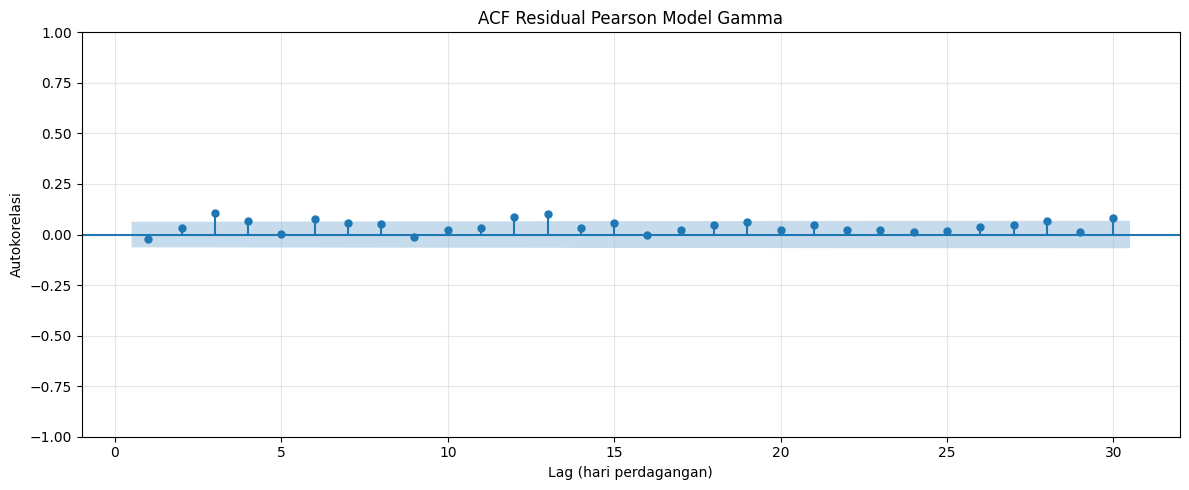

In [ ]:
import matplotlib.pyplot as plt
from statsmodels.graphics.tsaplots import plot_acf
from statsmodels.stats.diagnostic import acorr_ljungbox

# Menggunakan residual Pearson dari model Gamma
residual = pd.Series(
    hasil_gamma.resid_pearson,
    index=train.index
).dropna()

# Menentukan jumlah lag yang diperiksa
jumlah_lag = min(30, len(residual) // 2 - 1)

# Visualisasi ACF
fig, ax = plt.subplots(figsize=(12, 5))

plot_acf(
    residual,
    lags=jumlah_lag,
    alpha=0.05,
    zero=False,
    ax=ax
)

ax.set_title("ACF Residual Pearson Model Gamma")
ax.set_xlabel("Lag (hari perdagangan)")
ax.set_ylabel("Autokorelasi")
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

###7.11 Memeriksa lag dengan uji Ljung–Box

In [ ]:
# Menguji autokorelasi residual pada beberapa lag
daftar_lag = [
    lag for lag in [5, 10, 15, 20, 30]
    if lag < len(residual)
]

hasil_lb = acorr_ljungbox(
    residual,
    lags=daftar_lag,
    return_df=True
)

display(hasil_lb.round(4))

,lb_stat,lb_pvalue
5,16.8700,0.0048
10,28.8436,0.0013
15,51.6166,0.0000
20,58.4290,0.0000
30,77.2789,0.0000


###7.12 Interpretasi Autokorelasi Residual Model Gamma

Berdasarkan grafik Autocorrelation Function (ACF), sebagian besar nilai autokorelasi residual Pearson berada di sekitar nol, meskipun terdapat beberapa lag yang melewati batas kepercayaan. Hal ini mengindikasikan adanya kemungkinan ketergantungan residual pada beberapa lag.

Hasil uji Ljung–Box menunjukkan bahwa p-value pada lag 5, 10, 15, 20, dan 30 lebih kecil dari tingkat signifikansi 0,05. Dengan demikian, hipotesis nol yang menyatakan tidak adanya autokorelasi hingga lag yang diuji ditolak. Hasil ini menunjukkan bahwa residual model Gamma masih mengandung autokorelasi secara statistik.

Temuan tersebut mengindikasikan bahwa model belum sepenuhnya menangkap pola ketergantungan temporal dalam pergerakan pasar IHSG. Oleh karena itu, hasil diagnostik ini perlu dipertimbangkan dalam evaluasi model dan interpretasi hasil penelitian.

## 8. Pemodelan Regresi Gamma

Pemodelan dilakukan menggunakan Generalized Linear Model (GLM) dengan distribusi Gamma dan fungsi penghubung log (*log link*). Regresi Gamma digunakan karena variabel target, yaitu `Target_Range`, merupakan data numerik kontinu yang bernilai positif dan memiliki distribusi menceng ke kanan (*right-skewed*).

Variabel target didefinisikan sebagai rasio rentang pergerakan harga IHSG harian terhadap harga penutupan hari sebelumnya. Sementara itu, variabel prediktor menggunakan informasi dari hari perdagangan sebelumnya untuk menjelaskan besarnya pergerakan pasar pada hari berikutnya.

Variabel yang digunakan dalam pemodelan adalah:

- **Variabel target:** Target_Range
- **Variabel prediktor:** Lag_Return_1, Lag_Volatility_5, Lag_Range_1, dan Lag_Log_Volume_1.

Model dilatih menggunakan data latih (training data) yang telah dipisahkan secara kronologis dari data uji (testing data). Pemisahan ini bertujuan mempertahankan urutan waktu pada data pasar keuangan.

8.2 Menentukan bentuk model
GLM Gamma dengan log link memiliki bentuk umum:
\[
\log(\mu_t)=\beta_0+\beta_1X_{1,t}+\cdots+\beta_pX_{p,t}
\]

Keterangan:
- \(\mu_t\): nilai rata-rata Target_Range yang diperkirakan model.
- \(\beta_0\): intersep model.
- \(\beta_i\): koefisien masing-masing prediktor.
- \(X_{i,t}\): nilai variabel prediktor.
Log link memastikan prediksi rata-rata model bernilai positif, sesuai karakteristik distribusi Gamma.

###8.3 Kode Python — Melatih model Gamma
Kode ini menggunakan objek train, test, fitur_model, dan target_col yang telah dibuat pada tahap sebelumnya.

In [ ]:
import statsmodels.api as sm
import pandas as pd
import numpy as np

# Memisahkan prediktor dan target data latih
X_train = train[fitur_model].astype(float)
y_train = train[target_col].astype(float)

# Menambahkan intersep
X_train_const = sm.add_constant(X_train)

# Membentuk model GLM Gamma dengan log link
model_gamma = sm.GLM(
    y_train,
    X_train_const,
    family=sm.families.Gamma(
        link=sm.families.links.Log()
    )
)

# Melatih model
hasil_gamma = model_gamma.fit()

# Menampilkan ringkasan hasil model
print(hasil_gamma.summary())

                 Generalized Linear Model Regression Results                  
Dep. Variable:           Target_Range   No. Observations:                  955
Model:                            GLM   Df Residuals:                      950
Model Family:                   Gamma   Df Model:                            4
Link Function:                    Log   Scale:                         0.18057
Method:                          IRLS   Log-Likelihood:                 3909.3
Date:                Fri, 30 Oct 2026   Deviance:                       139.99
Time:                        04:07:46   Pearson chi2:                     172.
No. Iterations:                    11   Pseudo R-squ. (CS):             0.2110
Covariance Type:            nonrobust                                         
                       coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------------
const               -4.4909      0.287  

###8.4 Menampilkan koefisien model

In [ ]:
tabel_koefisien = pd.DataFrame({
    "Koefisien": hasil_gamma.params,
    "Std_Error": hasil_gamma.bse,
    "z_statistik": hasil_gamma.tvalues,
    "p_value": hasil_gamma.pvalues
})

display(tabel_koefisien.round(6))

,Koefisien,Std_Error,z_statistik,p_value
const,-4.490862,0.287448,-15.623213,0.000000
Lag_Return_1,-2.161391,1.645078,-1.313853,0.188896
Lag_Volatility_5,15.069951,3.388856,4.446914,0.000009
Lag_Range_1,25.274190,3.068979,8.235374,0.000000
Lag_Log_Volume_1,-0.021730,0.014988,-1.449860,0.147098


###8.5 Untuk memudahkan interpretasi, kita juga bisa mengubah koefisien menjadi exponentiated coefficients atau \(\exp(\beta)\).

In [ ]:
tabel_koefisien["Exp_Koefisien"] = np.exp(
    tabel_koefisien["Koefisien"]
)

display(tabel_koefisien.round(6))

,Koefisien,Std_Error,z_statistik,p_value,Exp_Koefisien
const,-4.490862,0.287448,-15.623213,0.000000,1.121100e-02
Lag_Return_1,-2.161391,1.645078,-1.313853,0.188896,1.151650e-01
Lag_Volatility_5,15.069951,3.388856,4.446914,0.000009,3.505875e+06
Lag_Range_1,25.274190,3.068979,8.235374,0.000000,9.471986e+10
Lag_Log_Volume_1,-0.021730,0.014988,-1.449860,0.147098,9.785040e-01


###8.6 menghitung faktor pengali ketika setiap prediktor naik 0,01 unit.

In [ ]:
import numpy as np
import pandas as pd

beta = hasil_gamma.params.drop("const")

interpretasi = pd.DataFrame({
    "Koefisien": beta,
    "Faktor_pengali_kenaikan_0.01": np.exp(beta * 0.01),
})

interpretasi["Perubahan_persen_0.01"] = (
    interpretasi["Faktor_pengali_kenaikan_0.01"] - 1
) * 100

display(interpretasi.round(4))

,Koefisien,Faktor_pengali_kenaikan_0.01,Perubahan_persen_0.01
Lag_Return_1,-2.1614,0.9786,-2.1382
Lag_Volatility_5,15.0700,1.1626,16.2647
Lag_Range_1,25.2742,1.2876,28.7551
Lag_Log_Volume_1,-0.0217,0.9998,-0.0217


###8.7 Kesimpulan Pemodelan Regresi Gamma

Hasil pemodelan Generalized Linear Model (GLM) dengan distribusi Gamma dan fungsi penghubung log menunjukkan bahwa Lag_Volatility_5 dan Lag_Range_1 memiliki koefisien positif dan signifikan secara statistik pada taraf signifikansi 5%. Hasil ini mengindikasikan bahwa volatilitas lima hari perdagangan sebelumnya dan rentang pergerakan IHSG pada hari sebelumnya memiliki hubungan positif dengan besarnya pergerakan IHSG pada hari berikutnya.

Sebaliknya, Lag_Return_1 dan Lag_Log_Volume_1 tidak menunjukkan hubungan yang signifikan secara statistik pada taraf 5% setelah memperhitungkan variabel prediktor lainnya. Temuan tersebut tidak berarti kedua variabel sama sekali tidak memiliki hubungan dengan target, tetapi bukti yang diperoleh dari model ini belum cukup untuk menyatakan adanya hubungan yang signifikan.

Hasil pemodelan ini selanjutnya perlu dievaluasi menggunakan data uji yang dipisahkan berdasarkan urutan waktu. Evaluasi tersebut diperlukan untuk mengetahui seberapa baik model memprediksi besarnya pergerakan IHSG pada data yang tidak digunakan selama pelatihan.

## 9. Evaluasi dan Interpretasi Model

Evaluasi model dilakukan untuk mengetahui kemampuan regresi Gamma dalam memprediksi besarnya pergerakan pasar IHSG pada data yang tidak digunakan selama pelatihan (out-of-sample testing).

Data dibagi secara kronologis menjadi 80% data latih dan 20% data uji. Model dilatih menggunakan data latih, sedangkan data uji digunakan untuk mengevaluasi kemampuan prediksi pada periode yang lebih baru.

Evaluasi dilakukan menggunakan Mean Absolute Error (MAE) dan Root Mean Squared Error (RMSE). Selain itu, nilai prediksi dibandingkan dengan nilai aktual melalui visualisasi deret waktu dan scatter plot. Koefisien model juga diinterpretasikan untuk memahami hubungan antara variabel prediktor dan rata-rata besarnya pergerakan IHSG.

Karena data pasar keuangan memiliki karakteristik temporal, hasil evaluasi perlu ditafsirkan dengan mempertimbangkan urutan waktu dan kemungkinan autokorelasi residual yang ditemukan pada tahap diagnostik.

###9.2 Uji out-of-sample
Gunakan model hasil_gamma yang sudah dilatih sebelumnya.

In [ ]:
import numpy as np
import pandas as pd
import statsmodels.api as sm

# Prediktor pada data uji
X_test = test[fitur_model].astype(float)

# Tambahkan intersep yang sama dengan model saat training
X_test_const = sm.add_constant(X_test, has_constant="add")

# Nilai aktual dan prediksi
y_test = test[target_col].astype(float)
y_pred = hasil_gamma.predict(X_test_const)

# Tabel aktual dan prediksi
hasil_prediksi = pd.DataFrame({
    "Aktual": y_test,
    "Prediksi": y_pred
}, index=test.index)

display(hasil_prediksi.head(10).round(6))

print("Jumlah data uji:", len(hasil_prediksi))
print("Tanggal awal data uji:", hasil_prediksi.index.min())
print("Tanggal akhir data uji:", hasil_prediksi.index.max())

,Aktual,Prediksi
Date,,
2025-10-24,0.009588,0.013835
2025-10-27,0.047814,0.011560
2025-10-28,0.013734,0.032394
2025-10-29,0.015633,0.012636
2025-10-30,0.010565,0.013019
2025-10-31,0.008733,0.011113
2025-11-03,0.009897,0.010776
2025-11-04,0.011017,0.010183
2025-11-05,0.016577,0.010990


Jumlah data uji: 239
Tanggal awal data uji: 2025-10-24 00:00:00
Tanggal akhir data uji: 2026-10-23 00:00:00


###9.3 Menghitung metrik error
Gunakan MAE dan RMSE. Keduanya mengukur selisih antara nilai aktual dan prediksi, tetapi memberikan bobot yang berbeda terhadap kesalahan besar

In [ ]:
from sklearn.metrics import mean_absolute_error, mean_squared_error

mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))

metrik = pd.DataFrame({
    "Metrik": ["MAE", "RMSE"],
    "Nilai": [mae, rmse]
})

display(metrik.round(6))

print(f"MAE  : {mae:.6f}")
print(f"RMSE : {rmse:.6f}")

,Metrik,Nilai
0,MAE,0.007832
1,RMSE,0.014443


MAE  : 0.007832
RMSE : 0.014443


###9.4baseline sederhana
Sebagai pembanding, kita bisa menggunakan rata-rata target pada data latih sebagai prediksi konstan untuk seluruh data uji. Ini membantu menjawab apakah model Gamma lebih baik daripada pendekatan sederhana.

In [ ]:
# Baseline: rata-rata target dari data training
prediksi_baseline = np.full(
    shape=len(y_test),
    fill_value=y_train.mean()
)

mae_baseline = mean_absolute_error(
    y_test, prediksi_baseline
)

rmse_baseline = np.sqrt(
    mean_squared_error(y_test, prediksi_baseline)
)

perbandingan_metrik = pd.DataFrame({
    "Model": ["Baseline rata-rata training", "Regresi Gamma"],
    "MAE": [mae_baseline, mae],
    "RMSE": [rmse_baseline, rmse]
})

display(perbandingan_metrik.round(6))

,Model,MAE,RMSE
0,Baseline rata-rata training,0.009057,0.014881
1,Regresi Gamma,0.007832,0.014443


###9.4 Visualisasi nilai aktual dan prediksi
Grafik ini membantu melihat apakah model mengikuti perubahan besarnya pergerakan IHSG selama periode pengujian.

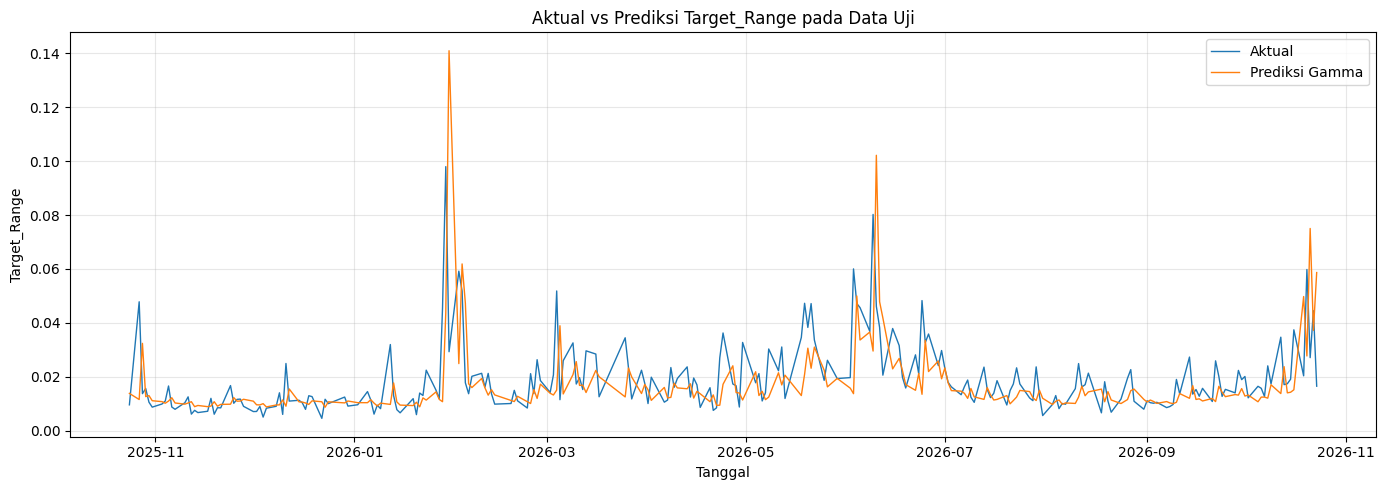

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(14, 5))

plt.plot(
    hasil_prediksi.index,
    hasil_prediksi["Aktual"],
    label="Aktual",
    linewidth=1
)

plt.plot(
    hasil_prediksi.index,
    hasil_prediksi["Prediksi"],
    label="Prediksi Gamma",
    linewidth=1
)

plt.title("Aktual vs Prediksi Target_Range pada Data Uji")
plt.xlabel("Tanggal")
plt.ylabel("Target_Range")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

###9.5 Periksa hubungan nilai aktual dan prediksi menggunakan scatter plot

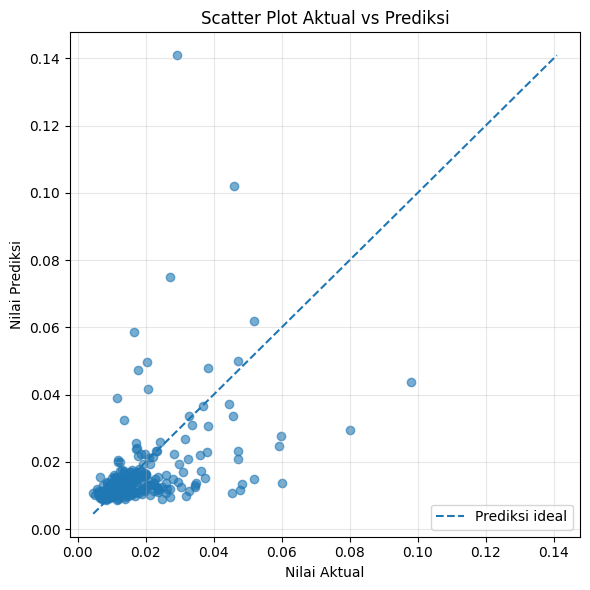

In [ ]:
plt.figure(figsize=(6, 6))

plt.scatter(
    hasil_prediksi["Aktual"],
    hasil_prediksi["Prediksi"],
    alpha=0.6
)

batas_min = min(
    hasil_prediksi["Aktual"].min(),
    hasil_prediksi["Prediksi"].min()
)

batas_max = max(
    hasil_prediksi["Aktual"].max(),
    hasil_prediksi["Prediksi"].max()
)

plt.plot(
    [batas_min, batas_max],
    [batas_min, batas_max],
    linestyle="--",
    label="Prediksi ideal"
)

plt.xlabel("Nilai Aktual")
plt.ylabel("Nilai Prediksi")
plt.title("Scatter Plot Aktual vs Prediksi")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

###9.6 Interpretasi koefisien dalam bentuk persentase
Dari hasil tahap 8, koefisien yang signifikan adalah Lag_Volatility_5 dan Lag_Range_1. Kita dapat menghitung perubahan relatif rata-rata target untuk kenaikan 0,01 unit pada masing-masing variabel, dengan variabel lain tetap.

In [ ]:
koef = hasil_gamma.params

variabel_signifikan = [
    "Lag_Volatility_5",
    "Lag_Range_1"
]

interpretasi_koef = pd.DataFrame({
    "Koefisien": koef[variabel_signifikan],
    "Perubahan_target_persen_kenaikan_0.01": [
        (np.exp(koef[var] * 0.01) - 1) * 100
        for var in variabel_signifikan
    ]
})

display(interpretasi_koef.round(4))

,Koefisien,Perubahan_target_persen_kenaikan_0.01
Lag_Volatility_5,15.0700,16.2647
Lag_Range_1,25.2742,28.7551


###9.7 Interpretasi hasil evaluasi
A. Perbandingan MAE dan RMSE

Model --	MAE, --	RMSE

Baseline rata-rata training	: 0,009057	0,014881

Regresi Gamma : 	0,007832	0,014443

Kedua metrik pada model Gamma lebih kecil dibandingkan baseline.

Artinya:
- MAE turun sekitar 13,52% dibandingkan baseline. Rata-rata kesalahan absolut model Gamma lebih rendah.
- RMSE turun sekitar 2,94% dibandingkan baseline. Kesalahan besar juga sedikit berkurang, tetapi peningkatannya relatif kecil.


Peningkatan performa model Gamma:\
Penurunan MAE
13,52%

Penurunan RMSE
2,94%


Interpretasi: Model Gamma memberikan hasil prediksi yang lebih baik daripada baseline sederhana. Namun, perbedaan RMSE yang relatif kecil menunjukkan bahwa model belum banyak memperbaiki kesalahan prediksi yang besar.

B. Interpretasi grafik aktual vs prediksi\
Dari pengamatan, garis prediksi Gamma mengikuti pola pergerakan aktual, tetapi terlihat bergeser sekitar satu hari.

Hal ini perlu diperhatikan.

Terdapat dua hal yang perlu dibedakan:
1. Model memang menggunakan variabel prediktor dari hari sebelumnya (Lag_Return_1, Lag_Volatility_5, dan seterusnya) untuk memprediksi target hari ini. Ini memang desain model yang gunakan.
2. Namun, hasil prediksi tetap harus dibandingkan dengan nilai aktual pada tanggal yang sama, tidak boleh menggeser tanggal prediksi hanya agar grafik terlihat lebih cocok.
Jika pola prediksi terlihat mengikuti pola aktual dengan keterlambatan satu hari, hal tersebut bisa menjadi indikasi bahwa model belum menangkap perubahan waktu secara optimal. Ini juga relevan dengan hasil autokorelasi residual pada tahap diagnostik sebelumnya.

Untuk memastikan tidak ada kesalahan penyelarasan tanggal, perlu pemeriksaan terhadap kesesuaian indeks tanggal

In [ ]:
# Memastikan tanggal aktual dan prediksi sama
print("Index aktual sama dengan prediksi:",
      y_test.index.equals(y_pred.index))

# Memeriksa beberapa tanggal pertama
display(
    pd.DataFrame({
        "Tanggal_Aktual": y_test.index,
        "Aktual": y_test.values,
        "Prediksi": y_pred.values
    }).head(15).round(6)
)

Index aktual sama dengan prediksi: True


,Tanggal_Aktual,Aktual,Prediksi
0,2025-10-24,0.009588,0.013835
1,2025-10-27,0.047814,0.011560
2,2025-10-28,0.013734,0.032394
3,2025-10-29,0.015633,0.012636
4,2025-10-30,0.010565,0.013019
5,2025-10-31,0.008733,0.011113
6,2025-11-03,0.009897,0.010776
7,2025-11-04,0.011017,0.010183
8,2025-11-05,0.016577,0.010990
9,2025-11-06,0.008779,0.012224


Pemeriksaan kesesuaian indeks tanggal antara nilai aktual dan prediksi menghasilkan nilai True. Hal ini menunjukkan bahwa kedua data telah memiliki penyelarasan waktu yang sesuai. Dengan demikian, pergeseran pola yang terlihat pada grafik bukan disebabkan oleh kesalahan penyelarasan tanggal, melainkan mengindikasikan bahwa model belum sepenuhnya mampu menangkap dinamika temporal pergerakan IHSG.

###9.8 Interpretasi Hasil Evaluasi Model

Berdasarkan hasil evaluasi *out-of-sample*, model Regresi Gamma menghasilkan nilai Mean Absolute Error (MAE) sebesar 0,007832 dan Root Mean Squared Error (RMSE) sebesar 0,014443. Sementara itu, model baseline yang menggunakan rata-rata target data latih menghasilkan MAE sebesar 0,009057 dan RMSE sebesar 0,014881.

Hasil tersebut menunjukkan bahwa model Regresi Gamma memiliki nilai kesalahan prediksi yang lebih rendah dibandingkan model baseline. Penurunan MAE sebesar 13,52% dan RMSE sebesar 2,94% menunjukkan adanya peningkatan kemampuan prediksi, meskipun peningkatan pada RMSE relatif kecil.

Berdasarkan visualisasi aktual dan prediksi, model Gamma mampu mengikuti sebagian pola perubahan besarnya pergerakan IHSG. Namun, terdapat indikasi pergeseran pola prediksi terhadap nilai aktual pada beberapa periode. Hal ini menunjukkan bahwa model belum sepenuhnya mampu menangkap perubahan temporal secara tepat.

Pada scatter plot, sebagian besar titik berada di sekitar garis diagonal yang menunjukkan kesesuaian antara nilai aktual dan prediksi. Meskipun demikian, masih terdapat beberapa titik yang berada cukup jauh dari garis diagonal. Kondisi ini mengindikasikan adanya observasi dengan kesalahan prediksi yang relatif besar.

Secara keseluruhan, model Regresi Gamma memberikan peningkatan performa dibandingkan baseline sederhana, tetapi kemampuan model dalam memprediksi pergerakan ekstrem dan menangkap pola temporal masih perlu diperhatikan. Hasil ini juga perlu diinterpretasikan bersama temuan autokorelasi residual pada tahap diagnostik sebelumnya.

## 10. Kesimpulan dan Keterbatasan Penelitian

Tahap ini bertujuan merangkum hasil analisis besarnya pergerakan pasar IHSG menggunakan regresi Gamma dengan fungsi penghubung log. Kesimpulan disusun berdasarkan hasil eksplorasi data, pemodelan, pemeriksaan diagnostik, dan evaluasi prediksi pada data uji.

###10.2 Kesimpulan berdasarkan hasil analisis
### A. Kesimpulan

Berdasarkan analisis data historis IHSG menggunakan metode Generalized Linear Model (GLM) dengan distribusi Gamma dan fungsi penghubung log, diperoleh beberapa kesimpulan sebagai berikut.

1. Variabel target Target_Range memiliki distribusi menceng ke kanan (right-skewed) dengan nilai skewness sebesar 3,4588. Hal ini menunjukkan bahwa sebagian besar pergerakan harian memiliki rentang relatif kecil, sementara beberapa periode menunjukkan rentang pergerakan yang lebih besar.

2. Hasil pemodelan menunjukkan bahwa Lag_Volatility_5 dan Lag_Range_1 memiliki hubungan positif dan signifikan secara statistik terhadap besarnya pergerakan IHSG. Sementara itu, `Lag_Return_1 dan Lag_Log_Volume_1 belum menunjukkan hubungan yang signifikan pada taraf 5%.

3. Hasil pemeriksaan multikolinearitas menunjukkan nilai VIF yang relatif mendekati 1, sehingga tidak ditemukan indikasi multikolinearitas yang kuat di antara variabel prediktor.

4. Pemeriksaan residual menggunakan uji Ljung–Box menunjukkan adanya autokorelasi residual pada beberapa lag yang diuji. Hal ini mengindikasikan bahwa model belum sepenuhnya menangkap ketergantungan temporal dalam data IHSG.

5. Evaluasi out-of-sample menunjukkan bahwa model Regresi Gamma menghasilkan MAE sebesar 0,007832 dan RMSE sebesar 0,014443. Nilai tersebut lebih rendah dibandingkan model baseline yang menghasilkan MAE sebesar 0,009057 dan RMSE sebesar 0,014881. Dengan demikian, model Gamma memberikan peningkatan performa prediksi dibandingkan baseline sederhana.

Secara keseluruhan, regresi Gamma dapat digunakan untuk memodelkan besarnya rentang pergerakan harian IHSG berdasarkan variabel historis yang digunakan. Namun, adanya autokorelasi residual dan keterbatasan dalam menangkap beberapa perubahan ekstrem menunjukkan bahwa masih terdapat ruang untuk pengembangan model lebih lanjut.

### B. Keterbatasan Penelitian

Penelitian ini memiliki beberapa keterbatasan, yaitu:

1. Penelitian hanya menggunakan data historis IHSG dari Yahoo Finance dengan variabel OHLCV, sehingga belum mempertimbangkan faktor eksternal seperti suku bunga, inflasi, nilai tukar, maupun kondisi ekonomi global.

2. Hasil diagnostik menunjukkan adanya autokorelasi residual, sehingga model belum sepenuhnya menangkap pola ketergantungan waktu pada data pasar.

3. Peningkatan performa model terhadap baseline masih relatif terbatas, terutama berdasarkan metrik RMSE. Hal ini menunjukkan bahwa model masih mengalami kesulitan dalam menangani beberapa kesalahan prediksi yang besar.

4. Penelitian menggunakan satu pendekatan pemodelan, yaitu GLM Gamma dengan fungsi penghubung log. Oleh karena itu, belum diketahui apakah pendekatan lain yang mempertimbangkan karakteristik deret waktu dapat memberikan hasil prediksi yang lebih baik.

###10.3 Saran pengembangan proyek

1. Gamma GLM dengan variabel temporal tambahan untuk	Menangkap dinamika pergerakan pasar
2. Model GARCH untuk Mengkaji dinamika volatilitas dan pengelompokan volatilitas
3. Perbandingan model	untuk Menilai apakah Gamma lebih baik daripada pendekatan alternatif